# ISO 20414:2020 — Test 14: Group Behaviour

A room of size 15 m x 20 m with a 1 m exit (ISO 20414:2020 Table 16). Two groups of occupants of size 5,10 in Zone 1 and Zone 2, respectively. 4 out of 5 occupants Group 1 has walking speed of 1,55 m/s whereas the fifth one has 0,8 m/s. The group of 10 uniformly occupying Zone 2 has a smaller walking speed of 0,5 m/s. The occupants in Zone 1 have to reach the exit of the room. The expected result is that the occupants of Group 1 will reach the exit together (i.e. the times for occupants of Group 1 to reach the exit should not differ more than 10s)

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 17:29 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario, run_sweep

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

In [4]:
import numpy as np

# House style for the V&V figures (plain matplotlib; applied per figure via rc_context).
from matplotlib.colors import to_rgba
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, PathPatch
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.path import Path as MplPath

VV_BLUE, VV_ORANGE, VV_RED, VV_GREEN = "#0072B2", "#E69F00", "#D55E00", "#009E73"
VV_RC = {
    "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 150,
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.grid": True, "grid.color": "#e5e5e5", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "lightgrey", "axes.labelcolor": "dimgrey",
    "axes.titlecolor": "#333333", "axes.titleweight": "normal", "axes.titlesize": 11,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": "dimgrey", "ytick.color": "dimgrey",
    "xtick.major.size": 0, "ytick.major.size": 0,
    "legend.frameon": True, "legend.facecolor": "white", "legend.framealpha": 0.8,
    "legend.edgecolor": "lightgrey", "legend.labelcolor": "dimgrey", "legend.fontsize": 9,
}


def vv_polygon_patch(geom, **kwargs):
    """Matplotlib patch for a shapely (Multi)Polygon, holes included."""
    verts, codes = [], []
    for part in getattr(geom, "geoms", [geom]):
        for ring in [part.exterior, *part.interiors]:
            xy = np.asarray(ring.coords)
            verts.extend(xy)
            codes += [MplPath.MOVETO] + [MplPath.LINETO] * (len(xy) - 2) + [MplPath.CLOSEPOLY]
    return PathPatch(MplPath(verts, codes), **kwargs)


def vv_draw_scenario(ax, scenario, starts=True, pad=0.04):
    """Draw walkable area, exits and start areas of a loaded scenario; return legend handles."""
    ax.add_patch(vv_polygon_patch(scenario.walkable_polygon, facecolor="#eeeeee",
                                  edgecolor="dimgrey", linewidth=1.4, zorder=1))
    handles = [Patch(facecolor="#eeeeee", edgecolor="dimgrey", label="walkable area")]
    if starts:
        for dist in scenario.distributions.values():
            ax.add_patch(MplPolygon(dist["coordinates"], closed=True,
                                    facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                                    linestyle="--", linewidth=1.2, hatch="..", zorder=2))
        handles.append(Patch(facecolor=to_rgba(VV_BLUE, 0.15), edgecolor=VV_BLUE,
                             linestyle="--", hatch="..", label="start area"))
    for ex in scenario.exits.values():
        ax.add_patch(MplPolygon(ex["coordinates"], closed=True,
                                facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                                linewidth=1.2, hatch="///", zorder=3))
    if scenario.exits:
        handles.append(Patch(facecolor=to_rgba(VV_RED, 0.35), edgecolor=VV_RED,
                             hatch="///", label="exit"))
    minx, miny, maxx, maxy = scenario.walkable_polygon.bounds
    m = pad * max(maxx - minx, maxy - miny)
    ax.set_xlim(minx - m, maxx + m)
    ax.set_ylim(miny - m, maxy + m)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    return handles


def vv_agent_count(scenario):
    """Total number of agents placed by the scenario's start areas."""
    return sum(int(d.get("parameters", {}).get("number", 0)) for d in scenario.distributions.values())

## Load and Run

In [5]:
%%capture 
SCENARIO_ZIP = Path("scenario_files") / "Iso-14-group-behaviour.zip"
scenario = load_scenario(str(SCENARIO_ZIP))
result = run_scenario(scenario, seed=4)

In [6]:
print(scenario.summary())
walkable = scenario.walkable_polygon
df = result.trajectory_dataframe()

Scenario: scenario_files/Iso-14-group-behaviour.zip
  Model:         CollisionFreeSpeedModel
  Seed:          42
  Max time:      300s
  Exits:         1
  Distributions: 2
  Stages:        0
  Zones:         0
  Journeys:      0
  Agents:        ~15
    jps-distributions_0: 5 agents
    jps-distributions_1: 10 agents


## Scenario figure

Room geometry from the loaded scenario with the two start areas.

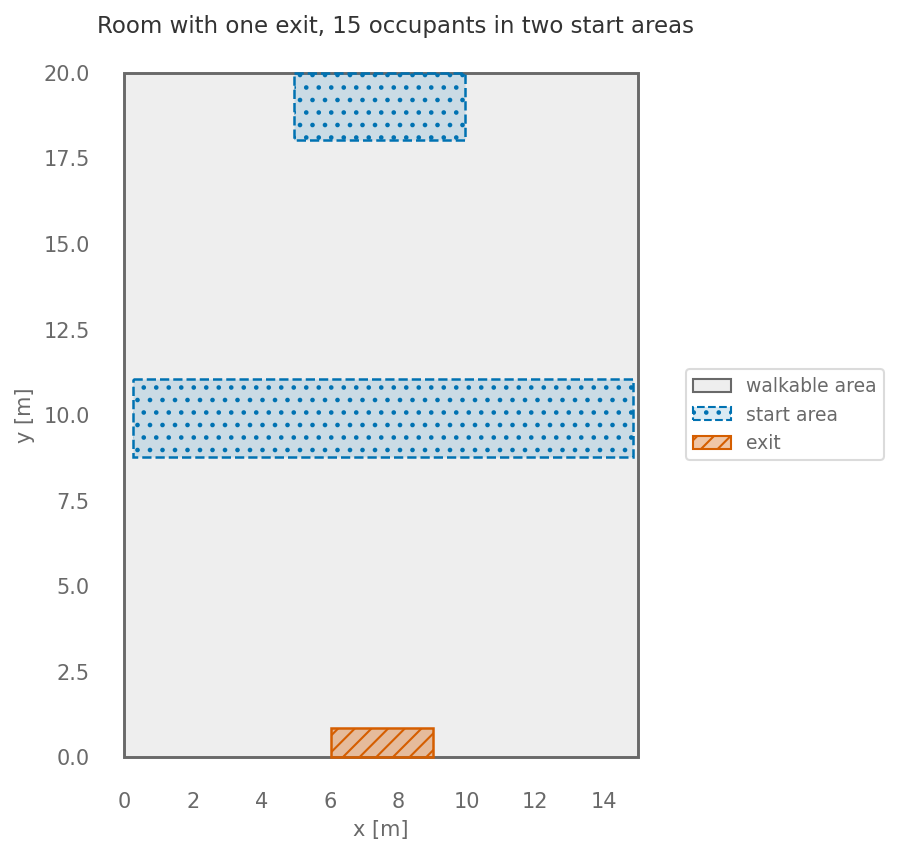

In [7]:
# Scenario geometry from the loaded ZIP.
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(5.2, 6.4))
    handles = vv_draw_scenario(ax, scenario)
    ax.set_title(f"Room with one exit, {vv_agent_count(scenario)} occupants in two start areas", loc="left")
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.02, 0.5))
    plt.show()

## Exit Times of Group 1

In [8]:
group_1_id = [1,2,3,4,5]
df_group_1=df[df["id"].isin(group_1_id)].sort_values(["id","frame"])

exit_rows = []
for agent_id, sub in df_group_1.groupby("id"):
    exit_time = sub.iloc[-1]["frame"] / result.frame_rate
    exit_rows.append({
        "id": int(agent_id),
        "exit_time_s": exit_time
    })
exit_times= pd.DataFrame(exit_rows).sort_values("exit_time_s")
exit_times


,id,exit_time_s
1,2,14.0
3,4,14.0
2,3,14.3
4,5,15.1
0,1,17.6


## Plot Trajectories

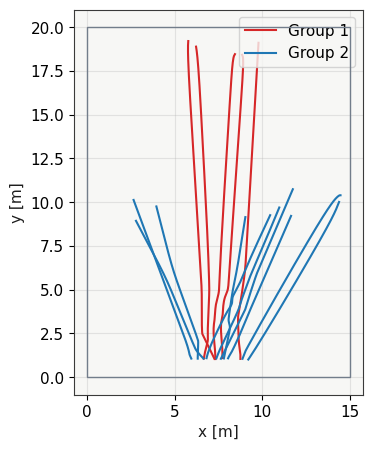

In [9]:
df_plot = df[["id", "frame", "x", "y"]].copy()
df_plot["is_group_1"] = df_plot["id"].isin(group_1_id)
traj = pedpy.TrajectoryData(df_plot[['id', 'frame', 'x', 'y']].copy(), frame_rate=result.frame_rate)
wa = pedpy.WalkableArea(walkable)
fig, ax = plt.subplots()

pedpy.plot_walkable_area(walkable_area=wa, axes=ax)

for agent_id, sub in df_plot.sort_values(["id", "frame"]).groupby("id"):
    color = "tab:red" if agent_id in group_1_id else "tab:blue"
    ax.plot(sub["x"],sub["y"],color=color)
ax.plot([], [], color="tab:red", label="Group 1")
ax.plot([], [], color="tab:blue", label="Group 2")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.show()

## Result figure

Exit time of each Group 1 occupant. Acceptance: the spread between first and last Group 1 exit stays within the limit.

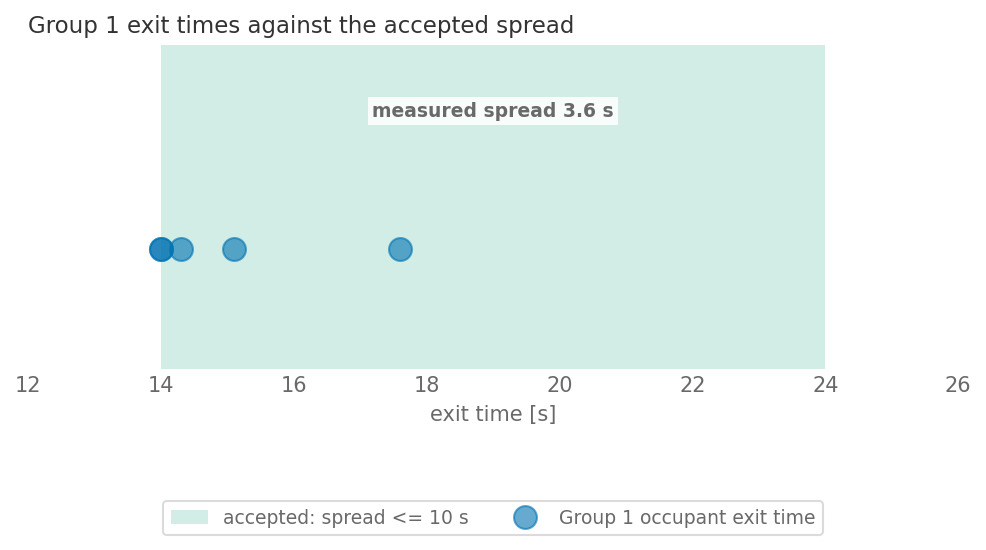

In [10]:
# Exit time of every Group 1 occupant against the allowed spread.
MAX_SPREAD_S = 10.0  # same value as the acceptance cell
t = exit_times["exit_time_s"].to_numpy()
with plt.rc_context(VV_RC):
    fig, ax = plt.subplots(figsize=(8, 2.8))
    ax.axvspan(t.min(), t.min() + MAX_SPREAD_S, facecolor=to_rgba(VV_GREEN, 0.18), edgecolor=VV_GREEN,
               lw=0, label=f"accepted: spread <= {MAX_SPREAD_S:g} s")
    ax.plot(t, np.zeros(len(t)), "o", color=VV_BLUE, alpha=0.6, ms=11, zorder=4, label="Group 1 occupant exit time")
    ax.set_xlim(t.min() - 2, max(t.max(), t.min() + MAX_SPREAD_S) + 2)
    ax.set_ylim(-1, 1.7)
    ax.set_yticks([])
    ax.set_xlabel("exit time [s]")
    ax.set_title("Group 1 exit times against the accepted spread", loc="left")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.38), ncol=2)
    ax.text(0.5, 0.78, f"measured spread {t.max() - t.min():.1f} s", transform=ax.transAxes, ha="center",
            color="dimgrey", fontweight="semibold", fontsize=9,
            bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 2})
    ax.grid(False)
    plt.show()

## Acceptance 

In [11]:
exit_diff = exit_times["exit_time_s"].max() - exit_times["exit_time_s"].min()
MAX_GROUP_EXIT_DIFF_S=10.0
assert exit_diff <= MAX_GROUP_EXIT_DIFF_S
print(f'evacuation time={result.evacuation_time:.2f}s')
result.cleanup()

evacuation time=21.92s


1